In [ ]:
# ====================================================================
# ANIP CHALLENGE - TÂCHE 1: RECONNAISSANCE FACIALE ROBUSTE
# Cellule 1 (robuste) — Installation / imports / configuration GPU & seeds
# ====================================================================

import os
import sys
import warnings
warnings.filterwarnings("ignore")

# --- Montage de Google Drive (essentiel dans Colab) ---
from google.colab import drive
mount_point = "/content/drive"

# Vérification simplifiée du montage
if not os.path.ismount(mount_point):
    print("🔌 Montage de Google Drive...")
    # Le montage peut parfois demander une autorisation
    try:
        drive.mount(mount_point, force_remount=True)
        print("✅ Google Drive monté.")
    except Exception as e:
        print(f"❌ Erreur lors du montage de Google Drive: {e}")
        # Poursuivre, mais les accès au drive échoueront.
else:
    print("🔌 Google Drive déjà monté.")

# --- Installation des packages manquants ---
# Dans Colab, on peut simplifier en installant directement si un package est requis.
# On utilise une liste simple car l'installation est requise.

_required_packages = [
    "plotly",
    "seaborn",
    "tqdm",
    "scikit-learn", # Ajouté, car beaucoup de métriques sont utilisées
    "opencv-python" # Ajouté, car cv2 est importé
]

def _install_packages(pkgs: list):
    import importlib
    import subprocess
    to_install = []

    # On vérifie si les modules sont installés, sinon on ajoute à la liste
    # Note: On utilise le nom du module Python (ex: 'cv2' pour 'opencv-python')
    module_names = {
        "plotly": "plotly",
        "seaborn": "seaborn",
        "tqdm": "tqdm",
        "scikit-learn": "sklearn",
        "opencv-python": "cv2"
    }

    # Liste des packages à vérifier (pour ne pas tout réinstaller)
    check_modules = [module_names.get(p, p) for p in pkgs]

    for pip_name, module_name in module_names.items():
        if module_name in check_modules and importlib.util.find_spec(module_name) is None:
            to_install.append(pip_name)

    if to_install:
        print("📦 Installation des packages manquants:", to_install)
        # Installation silencieuse standard compatible Colab
        try:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *to_install])
            print("✅ Installation terminée.")
        except subprocess.CalledProcessError as e:
            print(f"⚠️ Problème lors de l'installation des packages: {e}")
    else:
        print("✅ Tous les packages requis semblent déjà installés.")

_install_packages(_required_packages)

# --- Imports principaux (avec messages d'échec clairs) ---
try:
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import seaborn as sns
    import plotly
    import plotly.express as px
    import plotly.graph_objects as go
    from plotly.subplots import make_subplots
    from tqdm.auto import tqdm
except Exception as e:
    raise ImportError(f"❌ Erreur import visualisation/utilitaires: {e}")

# TensorFlow & Keras
try:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers, Model
    # on ne force pas un backbone ici — on importe le plus courant
    from tensorflow.keras.applications import MobileNetV2
    from tensorflow.keras.optimizers import Adam
    from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
    from tensorflow.keras.preprocessing.image import ImageDataGenerator
except Exception as e:
    raise ImportError(f"❌ Erreur import TensorFlow/Keras: {e}")

# Utilitaires supplémentaires (tolérance sur l'absence)
try:
    import cv2
except Exception as e:
    # Ce message est désormais moins probable si 'opencv-python' est dans la liste d'installation
    print("⚠️ OpenCV (cv2) non trouvé:", e)

try:
    from PIL import Image
    import zipfile
    import random
    from sklearn.model_selection import train_test_split
    from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                                 recall_score, roc_auc_score, roc_curve, confusion_matrix)
    from sklearn.manifold import TSNE
    from sklearn.preprocessing import StandardScaler
    import pickle
    from datetime import datetime
except Exception as e:
    # Ce message est désormais moins probable si 'scikit-learn' est dans la liste d'installation
    print("⚠️ Certains utilitaires/scikit peuvent manquer:", e)

# --- GPU / TF configuration (safe) ---
gpus = tf.config.list_physical_devices('GPU')
print("\n🔎 TF version:", tf.__version__)
if gpus:
    try:
        # activation de memory growth pour tous les GPUs détectés — évite OOM au démarrage
        for gpu in gpus:
            try:
                tf.config.experimental.set_memory_growth(gpu, True)
            except Exception as e:
                print("⚠️ set_memory_growth a échoué pour un GPU:", e)
        logical_gpus = tf.config.list_logical_devices('GPU')
        print(f"✅ {len(gpus)} GPU(s) détecté(s), {len(logical_gpus)} logique(s).")
    except Exception as e:
        print("⚠️ Impossible de configurer la mémoire GPU:", e)
else:
    print("ℹ️ Aucun GPU détecté — exécution sur CPU.")

# --- Seeds pour reproductibilité plus complète ---
SEED = int(os.environ.get("PROJECT_SEED", 42))
np.random.seed(SEED)
random.seed(SEED)
try:
    tf.random.set_seed(SEED)
except Exception:
    pass

# Optionnel: forcer TF determinism
try:
    os.environ.setdefault("PYTHONHASHSEED", "0")
    os.environ.setdefault("TF_DETERMINISTIC_OPS", "1")
    # Limitation threads (aide la reproductibilité)
    tf.config.threading.set_inter_op_parallelism_threads(1)
    tf.config.threading.set_intra_op_parallelism_threads(1)
except Exception:
    pass

# --- Résumé final utile pour debug ---
print("\n📋 Résumé environnement:")
# L'environnement Colab est implicite, on enlève la variable IN_COLAB non définie.
print(f"  - Python: {sys.version.split()[0]}")
print(f"  - NumPy: {np.__version__}")
print(f"  - Pandas: {pd.__version__}")

import matplotlib
print(f"  - Matplotlib: {matplotlib.__version__}")
# Utilisation de getattr pour une vérification plus robuste
print(f"  - Seaborn: {getattr(sns, '__version__', 'unknown')}")
print(f"  - Plotly: {getattr(plotly, '__version__', 'unknown')}")
print(f"  - Tqdm: {getattr(tqdm, '__version__', 'unknown')}")
print(f"  - TF/Keras: {tf.__version__} / {keras.__version__}")
print(f"  - GPU count: {len(gpus)}")
print("🎉 Imports et configuration terminés\n")

🔌 Montage de Google Drive...
Mounted at /content/drive
🔎 TF version: 2.19.0
✅ 1 GPU(s) détecté(s), 1 logique(s).

📋 Résumé environnement:
  - En Colab: True
  - Python: 3.12.11
  - NumPy: 2.0.2
  - Pandas: 2.2.2
  - Matplotlib: 3.10.0
  - Seaborn: 0.13.2
  - Plotly: 5.24.1
  - Tqdm: tqdm
  - TF/Keras: 2.19.0 / 3.10.0
  - GPU count: 1
✓ Imports et configuration terminés



In [ ]:
# ====================================================================
# ANIP CHALLENGE - TÂCHE 1: RECONNAISSANCE FACIALE ROBUSTE
# Cellule 2 — Configuration des chemins et hyperparamètres (robuste)
# ====================================================================

import os

# ------------------------------
# Configuration des chemins
# ------------------------------
BASE_PATH = "/content/drive/MyDrive/ANIP_Challenge/Datasets/"
DATASET_ZIP = os.path.join(BASE_PATH, "dataset_tache_1.zip")
EXTRACT_PATH = "/content/anip_data/"
TRAIN_PATH = os.path.join(EXTRACT_PATH, "dataset_tache_1", "train")
TEST_PATH = os.path.join(EXTRACT_PATH, "dataset_tache_1", "test")

MODEL_SAVE_PATH = "/content/drive/MyDrive/ANIP_Challenge/Models/"
RESULTS_PATH = "/content/drive/MyDrive/ANIP_Challenge/Results/"

# Création des dossiers de sauvegarde (sécurisé)
for path in [MODEL_SAVE_PATH, RESULTS_PATH, EXTRACT_PATH]:
    os.makedirs(path, exist_ok=True)

# ------------------------------
# Hyperparamètres du modèle
# ------------------------------
CONFIG = {
    'DATA': {
        'IMG_HEIGHT': 224,
        'IMG_WIDTH': 224,
        'IMG_CHANNELS': 3,
        'BATCH_SIZE': 64,
        'VALIDATION_SPLIT': 0.2,
    },
    'TRAINING': {
        'EPOCHS': 50,
        'LEARNING_RATE': 1e-4,
        'FINE_TUNE_RATE': 1e-5,
        'PATIENCE': 8,
        'MIN_DELTA': 1e-4,
    },
    'MODEL': {
        'EMBEDDING_DIM': 256,
        'DROPOUT_RATE': 0.3,
        'L2_REG': 1e-4,
    },
    'PAIR_GENERATION': {
        'PAIRS_PER_IDENTITY': 10,   # paires positives par identité
        'NEGATIVE_RATIO': 1.5,      # ratio négatif/positif
    },
    'THRESHOLDS': {
        'TARGET_ACCURACY': 0.80,
        'DISTANCE_THRESHOLD': 0.7,
        'MARGIN': 1.0,
    }
}

# ------------------------------
# Augmentations légères
# ------------------------------
AUGMENTATION_CONFIG = {
    'rotation_range': 10,
    'width_shift_range': 0.1,
    'height_shift_range': 0.1,
    'shear_range': 0.1,
    'zoom_range': 0.1,
    'horizontal_flip': True,
    'brightness_range': [0.9, 1.1],
    'fill_mode': 'nearest'
}

# ------------------------------
# Vérification dataset
# ------------------------------
def count_images_in_dir(path):
    exts = (".jpg", ".jpeg", ".png", ".bmp")
    return sum([1 for root, _, files in os.walk(path) for f in files if f.lower().endswith(exts)])

train_count = count_images_in_dir(TRAIN_PATH) if os.path.exists(TRAIN_PATH) else 0
test_count = count_images_in_dir(TEST_PATH) if os.path.exists(TEST_PATH) else 0

# ------------------------------
# Vérification et affichage
# ------------------------------
print("=== Configuration du projet ===")

# Vérification des chemins critiques
print("\n✓ Chemins configurés:")
print(f"  - Dataset ZIP: {DATASET_ZIP} {'[OK]' if os.path.exists(DATASET_ZIP) else '[NON TROUVÉ]'}")
print(f"  - Extraction: {EXTRACT_PATH}")
print(f"  - Train dir: {TRAIN_PATH} ({train_count} images) {'[OK]' if train_count > 0 else '[VIDE/ABSENT]'}")
print(f"  - Test dir:  {TEST_PATH} ({test_count} images) {'[OK]' if test_count > 0 else '[VIDE/ABSENT]'}")
print(f"  - Sauvegarde modèle: {MODEL_SAVE_PATH}")
print(f"  - Sauvegarde résultats: {RESULTS_PATH}")

# Affichage des hyperparamètres
print("\n✓ Hyperparamètres:")
for section, params in CONFIG.items():
    print(f"\n[{section}]")
    for key, value in params.items():
        print(f"  - {key}: {value}")

print("\n✓ Augmentation configurée")
print("✓ Configuration terminée\n")


=== Configuration du projet ===

✓ Chemins configurés:
  - Dataset ZIP: /content/drive/MyDrive/ANIP_Challenge/Datasets/dataset_tache_1.zip [OK]
  - Extraction: /content/anip_data/
  - Train dir: /content/anip_data/dataset_tache_1/train (0 images) [VIDE/ABSENT]
  - Test dir:  /content/anip_data/dataset_tache_1/test (0 images) [VIDE/ABSENT]
  - Sauvegarde modèle: /content/drive/MyDrive/ANIP_Challenge/Models/
  - Sauvegarde résultats: /content/drive/MyDrive/ANIP_Challenge/Results/

✓ Hyperparamètres:

[DATA]
  - IMG_HEIGHT: 224
  - IMG_WIDTH: 224
  - IMG_CHANNELS: 3
  - BATCH_SIZE: 64
  - VALIDATION_SPLIT: 0.2

[TRAINING]
  - EPOCHS: 50
  - LEARNING_RATE: 0.0001
  - FINE_TUNE_RATE: 1e-05
  - PATIENCE: 8
  - MIN_DELTA: 0.0001

[MODEL]
  - EMBEDDING_DIM: 256
  - DROPOUT_RATE: 0.3
  - L2_REG: 0.0001

[PAIR_GENERATION]
  - PAIRS_PER_IDENTITY: 10
  - NEGATIVE_RATIO: 1.5

[THRESHOLDS]
  - TARGET_ACCURACY: 0.8
  - DISTANCE_THRESHOLD: 0.7
  - MARGIN: 1.0

✓ Augmentation configurée
✓ Configuration

🔄 Extraction du dataset...
✓ Extraction réussie

🔍 Analyse de la structure du dataset...
📊 Dataset Stats:
  - Images train: 4000
  - Identités uniques: 2000
  - Images test: 2000
  - Images/identité (min/max/moy): 2/2/2.0

📝 Exemples:
  - 0000: ['0000_0.jpg', '0000_1.jpg']
  - 0001: ['0001_0.jpg', '0001_1.jpg']
  - 0002: ['0002_0.jpg', '0002_1.jpg']
  - 0003: ['0003_0.jpg', '0003_1.jpg']
  - 0004: ['0004_0.jpg', '0004_1.jpg']

✓ Dataset prêt pour l'entraînement
✓ Test image OK - Shape: (224, 224, 3)


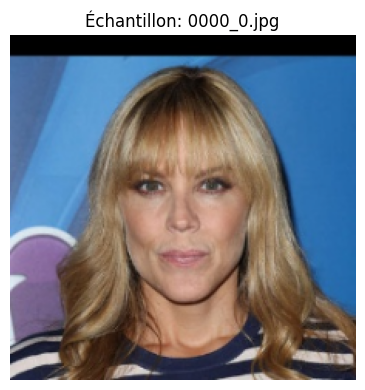

In [ ]:
# ====================================================================
# Cellule 3: Extraction et préparation des données (robuste)
# ====================================================================

import zipfile
import cv2
import numpy as np
import matplotlib.pyplot as plt

def extract_dataset():
    """
    Extrait le dataset depuis le fichier ZIP
    """
    print("🔄 Extraction du dataset...")

    if not os.path.exists(DATASET_ZIP):
        print(f"❌ Fichier ZIP non trouvé: {DATASET_ZIP}")
        return False

    os.makedirs(EXTRACT_PATH, exist_ok=True)

    try:
        with zipfile.ZipFile(DATASET_ZIP, 'r') as zip_ref:
            zip_ref.extractall(EXTRACT_PATH)
        print("✓ Extraction réussie")
        return True
    except Exception as e:
        print(f"❌ Erreur lors de l'extraction: {e}")
        return False


def analyze_dataset_structure():
    """
    Analyse la structure du dataset et collecte les informations
    """
    print("\n🔍 Analyse de la structure du dataset...")

    if not os.path.exists(TRAIN_PATH) or not os.path.exists(TEST_PATH):
        print("❌ Dossier train/test manquant")
        return None

    # Extensions supportées
    valid_exts = ('.jpg', '.jpeg', '.png', '.bmp')

    # Train
    train_files = [f for f in os.listdir(TRAIN_PATH) if f.lower().endswith(valid_exts)]
    train_files.sort()

    train_identities = {}
    for file in train_files:
        if '_' in file:
            identity = file.split('_')[0]
            train_identities.setdefault(identity, []).append(file)

    # Test
    test_files = [f for f in os.listdir(TEST_PATH) if f.lower().endswith(valid_exts)]
    test_files.sort()

    # Statistiques
    identity_counts = [len(files) for files in train_identities.values()]
    print(f"📊 Dataset Stats:")
    print(f"  - Images train: {len(train_files)}")
    print(f"  - Identités uniques: {len(train_identities)}")
    print(f"  - Images test: {len(test_files)}")
    if identity_counts:
        print(f"  - Images/identité (min/max/moy): {min(identity_counts)}/{max(identity_counts)}/{np.mean(identity_counts):.1f}")

    # Vérif cohérence
    for identity, files in train_identities.items():
        if len(files) < 2:
            print(f"⚠️ Identité {identity} a seulement {len(files)} image(s) → insuffisant pour des paires")

    # Aperçu
    print("\n📝 Exemples:")
    for i, (identity, files) in enumerate(list(train_identities.items())[:5]):
        print(f"  - {identity}: {files}")

    return {
        'train_identities': train_identities,
        'test_files': test_files,
        'num_identities': len(train_identities),
        'num_train_images': sum(len(files) for files in train_identities.values()),
        'num_test_images': len(test_files)
    }


def load_and_preprocess_image(image_path, target_size=(224, 224)):
    """
    Charge et prétraite une image (robuste)
    """
    try:
        image = cv2.imread(image_path)
        if image is None:
            print(f"⚠️ Erreur lecture image: {image_path}")
            return None

        # BGR → RGB
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # Resize
        image = cv2.resize(image, target_size)

        # Normalisation [-1, 1] → mieux pour ResNet/EfficientNet
        image = image.astype(np.float32) / 127.5 - 1.0

        return image
    except Exception as e:
        print(f"❌ Erreur chargement {image_path}: {e}")
        return None


# ------------------------------
# Exécution
# ------------------------------
if extract_dataset():
    dataset_info = analyze_dataset_structure()

    if dataset_info:
        print("\n✓ Dataset prêt pour l'entraînement")

        # Test d'une image
        sample_identity = list(dataset_info['train_identities'].keys())[0]
        sample_file = dataset_info['train_identities'][sample_identity][0]
        sample_path = os.path.join(TRAIN_PATH, sample_file)

        sample_image = load_and_preprocess_image(sample_path)

        if sample_image is not None:
            print(f"✓ Test image OK - Shape: {sample_image.shape}")
            plt.figure(figsize=(6, 4))
            plt.imshow((sample_image + 1) / 2)  # re-normalisation [0,1] pour affichage
            plt.title(f"Échantillon: {sample_file}")
            plt.axis('off')
            plt.tight_layout()
            plt.show()
        else:
            print("❌ Erreur lors du test de chargement")
    else:
        print("❌ Analyse du dataset échouée")
else:
    print("❌ Extraction échouée")


🔍 Nettoyage des doublons...
⚠️ 2002 doublons supprimés
🔄 Génération des paires d'entraînement...
  - Paires positives: 998
  - Paires négatives: 1497
  - Total paires: 2495
  - Ratio pos/neg: 998/1497

📊 Répartition:
  - Train: 1996 paires
  - Val: 499 paires

🧪 Batch test:
  - img1 shape: (64, 224, 224, 3)
  - img2 shape: (64, 224, 224, 3)
  - labels distribution: {np.int64(0): np.int64(34), np.int64(1): np.int64(30)}


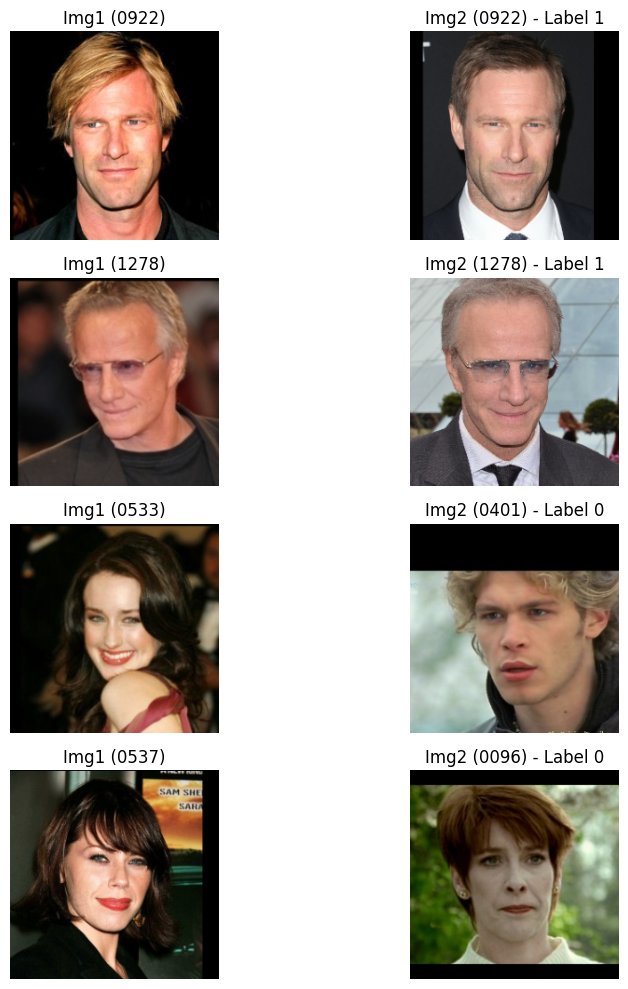

✓ Génération de paires terminée (robuste)


In [ ]:
# ====================================================================
# Cellule 4: Génération robuste de paires d'entraînement pour Siamese
# (avec nettoyage et protections)
# ====================================================================

import hashlib
from tensorflow.keras.utils import Sequence
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# --------------------------------------------------------------------
# Utilitaire: calcul hash perceptuel pour détecter les doublons
# --------------------------------------------------------------------
def get_image_hash(image_path, size=(32, 32)):
    try:
        img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
        if img is None:
            return None
        img = cv2.resize(img, size)
        return hashlib.md5(img.tobytes()).hexdigest()
    except:
        return None

# --------------------------------------------------------------------
# Générateur de paires
# --------------------------------------------------------------------
class PairGenerator:
    """
    Générateur de paires positives et négatives pour l'entraînement Siamese
    (avec nettoyage intégré)
    """

    def __init__(self, train_identities, train_path, config):
        # Initial filtering of identities with less than 2 images
        initial_identities = {k: v for k, v in train_identities.items() if len(v) >= 2}
        self.train_path = train_path
        self.config = config

        # Nettoyage des doublons
        print("🔍 Nettoyage des doublons...")
        self.train_identities = self.remove_duplicates(initial_identities)

        # Filter identities again after removing duplicates
        self.train_identities = {k: v for k, v in self.train_identities.items() if len(v) >= 2}
        self.identity_list = list(self.train_identities.keys())


    def remove_duplicates(self, identities_dict):
        """
        Supprime les doublons exacts par hash perceptuel
        """
        hashes = {}
        removed = 0
        cleaned_identities = {}
        for identity, files in identities_dict.items():
            unique_files = []
            for file in files:
                fpath = os.path.join(self.train_path, file)
                h = get_image_hash(fpath)
                if h and h not in hashes:
                    hashes[h] = file
                    unique_files.append(file)
                else:
                    removed += 1
            cleaned_identities[identity] = unique_files

        if removed > 0:
            print(f"⚠️ {removed} doublons supprimés")
        else:
            print("✓ Aucun doublon détecté")
        return cleaned_identities


    def generate_positive_pairs(self):
        """
        Génère des paires positives limitées par PAIRS_PER_IDENTITY
        """
        positive_pairs = []
        max_pairs = self.config.get('PAIRS_PER_IDENTITY', 10)

        for identity, files in self.train_identities.items():
            if len(files) >= 2:
                combos = [(files[i], files[j]) for i in range(len(files)) for j in range(i + 1, len(files))]
                if len(combos) > max_pairs:
                    combos = random.sample(combos, max_pairs)

                for f1, f2 in combos:
                    positive_pairs.append({
                        'image1': f1, 'image2': f2,
                        'identity1': identity, 'identity2': identity,
                        'label': 1
                    })
        return positive_pairs

    def generate_negative_pairs(self, num_negative):
        """
        Génère des paires négatives équilibrées
        """
        negative_pairs = []
        max_attempts = num_negative * 5
        attempts = 0

        while len(negative_pairs) < num_negative and attempts < max_attempts:
            if len(self.identity_list) < 2:
                 print("⚠️ Pas assez d'identités uniques pour générer des paires négatives.")
                 break
            id1, id2 = random.sample(self.identity_list, 2)
            # Ensure identities have images after cleaning
            if self.train_identities[id1] and self.train_identities[id2]:
                file1 = random.choice(self.train_identities[id1])
                file2 = random.choice(self.train_identities[id2])

                negative_pairs.append({
                    'image1': file1, 'image2': file2,
                    'identity1': id1, 'identity2': id2,
                    'label': 0
                })
            attempts += 1

        return negative_pairs

    def generate_all_pairs(self):
        """
        Génère toutes les paires équilibrées
        """
        print("🔄 Génération des paires d'entraînement...")

        positive_pairs = self.generate_positive_pairs()
        num_positive = len(positive_pairs)
        print(f"  - Paires positives: {num_positive}")

        num_negative = int(num_positive * self.config.get('NEGATIVE_RATIO', 1.5))
        negative_pairs = self.generate_negative_pairs(num_negative)
        print(f"  - Paires négatives: {len(negative_pairs)}")

        all_pairs = positive_pairs + negative_pairs
        random.shuffle(all_pairs)

        print(f"  - Total paires: {len(all_pairs)}")
        if num_positive > 0:
            print(f"  - Ratio pos/neg: {num_positive}/{len(negative_pairs)}")
        else:
            print("  - Pas de paires positives générées.")

        return all_pairs

# --------------------------------------------------------------------
# Générateur optimisé pour Keras
# --------------------------------------------------------------------
class SiameseDataGenerator(Sequence):
    """
    Générateur de batchs pour l'entraînement Siamese
    (robuste aux erreurs d'image)
    """

    def __init__(self, pairs, train_path, config, augment=False):
        self.pairs = pairs
        self.train_path = train_path
        self.batch_size = config['DATA'].get('BATCH_SIZE', 64)
        self.img_height = config['DATA'].get('IMG_HEIGHT', 224)
        self.img_width = config['DATA'].get('IMG_WIDTH', 224)
        self.augment = augment

        self.datagen = ImageDataGenerator(**AUGMENTATION_CONFIG) if augment else None
        self.on_epoch_end()

    def __len__(self):
        return max(1, len(self.pairs) // self.batch_size)

    def __getitem__(self, index):
        start = index * self.batch_size
        end = start + self.batch_size
        batch_pairs = self.pairs[start:end]

        images1 = np.zeros((len(batch_pairs), self.img_height, self.img_width, 3), dtype=np.float32)
        images2 = np.zeros((len(batch_pairs), self.img_height, self.img_width, 3), dtype=np.float32)
        labels = np.zeros(len(batch_pairs), dtype=np.float32)

        for i, pair in enumerate(batch_pairs):
            img1 = load_and_preprocess_image(os.path.join(self.train_path, pair['image1']), (self.img_height, self.img_width))
            img2 = load_and_preprocess_image(os.path.join(self.train_path, pair['image2']), (self.img_height, self.img_width))

            # Fallback si image illisible
            if img1 is None:
                img1 = np.zeros((self.img_height, self.img_width, 3), dtype=np.float32)
            if img2 is None:
                img2 = np.zeros((self.img_height, self.img_width, 3), dtype=np.float32)

            if self.augment:
                img1 = self.datagen.random_transform(img1)
                img2 = self.datagen.random_transform(img2)

            images1[i] = img1
            images2[i] = img2
            labels[i] = float(pair['label'])

        return (images1, images2), labels

    def on_epoch_end(self):
        random.shuffle(self.pairs)

# ====================================================================
# Exécution et tests
# ====================================================================
if 'dataset_info' in locals():
    pair_gen = PairGenerator(dataset_info['train_identities'], TRAIN_PATH, CONFIG['PAIR_GENERATION'])
    all_pairs = pair_gen.generate_all_pairs()

    # Add a check if all_pairs is empty after generation
    if not all_pairs:
        print("❌ Aucune paire générée. Vérifiez les données d'entrée et la configuration.")
    else:
        train_pairs, val_pairs = train_test_split(
            all_pairs,
            test_size=CONFIG['DATA'].get('VALIDATION_SPLIT', 0.2),
            random_state=SEED,
            stratify=[p['label'] for p in all_pairs]
        )

        print(f"\n📊 Répartition:")
        print(f"  - Train: {len(train_pairs)} paires")
        print(f"  - Val: {len(val_pairs)} paires")

        # Générateurs
        train_generator = SiameseDataGenerator(train_pairs, TRAIN_PATH, CONFIG, augment=True)
        val_generator = SiameseDataGenerator(val_pairs, TRAIN_PATH, CONFIG, augment=False)

        # Test batch
        (img1_batch, img2_batch), y_batch = train_generator[0]
        unique, counts = np.unique(y_batch.astype(int), return_counts=True)
        print(f"\n🧪 Batch test:")
        print(f"  - img1 shape: {img1_batch.shape}")
        print(f"  - img2 shape: {img2_batch.shape}")
        print(f"  - labels distribution: {dict(zip(unique, counts))}")

        # Visualisation 2 positives & 2 négatives
        fig, axes = plt.subplots(4, 2, figsize=(10, 10))
        sample_pairs = [p for p in train_pairs if p['label'] == 1][:2] + [p for p in train_pairs if p['label'] == 0][:2]

        for i, pair in enumerate(sample_pairs):
            img1 = load_and_preprocess_image(os.path.join(TRAIN_PATH, pair['image1']))
            img2 = load_and_preprocess_image(os.path.join(TRAIN_PATH, pair['image2']))

            axes[i, 0].imshow((img1 + 1) / 2)
            axes[i, 0].set_title(f"Img1 ({pair['identity1']})")
            axes[i, 0].axis("off")

            axes[i, 1].imshow((img2 + 1) / 2)
            axes[i, 1].set_title(f"Img2 ({pair['identity2']}) - Label {pair['label']}")
            axes[i, 1].axis("off")

        plt.tight_layout()
        plt.show()

        print("✓ Génération de paires terminée (robuste)")
else:
    print("❌ Dataset info manquant")

In [ ]:
# ====================================================================
# Cellule 5 (Optimisée): Architecture du modèle Siamese avec MobileNetV2
# ====================================================================

class SiameseModel:
    def __init__(self, config):
        self.config = config
        self.backbone = None
        self.embedding_model = None
        self.siamese_model = None

    def create_backbone(self):
        print("🏗️ Création du backbone MobileNetV2...")
        base_model = MobileNetV2(
            weights="imagenet",
            include_top=False,
            input_shape=(self.config.get('IMG_HEIGHT', 224),
                         self.config.get('IMG_WIDTH', 224), 3)
        )
        base_model.trainable = False

        inputs = keras.Input(shape=(self.config.get('IMG_HEIGHT', 224),
                                    self.config.get('IMG_WIDTH', 224), 3))
        x = base_model(inputs, training=False)
        x = layers.GlobalAveragePooling2D()(x)
        x = layers.Dense(512, activation='relu',
                         kernel_regularizer=keras.regularizers.l2(self.config.get('L2_REG', 1e-4)))(x)
        x = layers.Dropout(self.config.get('DROPOUT_RATE', 0.3))(x)
        x = layers.BatchNormalization()(x)
        x = layers.Dense(self.config.get('EMBEDDING_DIM', 128),
                         kernel_regularizer=keras.regularizers.l2(self.config.get('L2_REG', 1e-4)))(x)
        embeddings = layers.Lambda(lambda x: tf.nn.l2_normalize(x, axis=1),
                                   name='l2_normalize')(x)

        self.embedding_model = Model(inputs, embeddings, name="embedding_model")
        self.backbone = base_model
        print(f"✓ Backbone créé - Embedding dim: {self.config.get('EMBEDDING_DIM',128)}")
        return self.embedding_model

    def euclidean_distance(self, vectors):
        x, y = vectors
        # 💡 Utilisation de la distance au carré (plus stable que sqrt)
        return tf.reduce_sum(tf.square(x - y), axis=1, keepdims=True)

    def contrastive_loss(self, y_true, y_pred, margin=None):
        if margin is None:
            margin = self.config.get('MARGIN', 1.0)
        y_true = tf.cast(y_true, tf.float32)
        return tf.reduce_mean(
            y_true * y_pred + (1 - y_true) * tf.square(tf.maximum(margin - tf.sqrt(y_pred + 1e-6), 0))
        )

    def accuracy_metric(self, y_true, y_pred):
        threshold = self.config.get('DISTANCE_THRESHOLD', 0.5)
        y_true = tf.cast(y_true, tf.float32)
        predictions = tf.cast(y_pred < threshold, tf.float32)
        return tf.reduce_mean(tf.cast(tf.equal(predictions, y_true), tf.float32))

    def create_siamese_model(self):
        if self.embedding_model is None:
            self.create_backbone()
        input_1 = keras.Input(shape=(self.config.get('IMG_HEIGHT', 224),
                                     self.config.get('IMG_WIDTH', 224), 3))
        input_2 = keras.Input(shape=(self.config.get('IMG_HEIGHT', 224),
                                     self.config.get('IMG_WIDTH', 224), 3))
        embedding_1 = self.embedding_model(input_1)
        embedding_2 = self.embedding_model(input_2)
        distance = layers.Lambda(self.euclidean_distance, name="euclidean_distance")([embedding_1, embedding_2])
        self.siamese_model = Model([input_1, input_2], distance, name="siamese_model")
        print("✓ Modèle Siamese créé")
        return self.siamese_model

    def compile_model(self, learning_rate=None):
        if learning_rate is None:
            learning_rate = self.config.get('LEARNING_RATE', 1e-4)
        lr_schedule = keras.optimizers.schedules.ExponentialDecay(
            initial_learning_rate=learning_rate,
            decay_steps=10000,
            decay_rate=0.9
        )
        optimizer = Adam(learning_rate=lr_schedule)
        self.siamese_model.compile(
            optimizer=optimizer,
            loss=self.contrastive_loss,
            metrics=[self.accuracy_metric, "mae"]
        )
        print("✓ Modèle compilé")

    def enable_fine_tuning(self, learning_rate=None):
        if learning_rate is None:
            learning_rate = self.config.get('FINE_TUNE_RATE', 1e-5)
        print(f"🔓 Fine-tuning activé (LR={learning_rate})...")
        self.backbone.trainable = True
        # Déverrouiller les derniers blocs entiers de MobileNetV2
        for layer in self.backbone.layers[:-40]:
            layer.trainable = False
        self.compile_model(learning_rate)


In [ ]:
# ====================================================================
# Cellule 5.5: Test et vérification avant entraînement (améliorée)
# ====================================================================

print("🧪 Tests de compatibilité avant entraînement...")

# Vérifie que le modèle Siamese est créé et compilé
try:
    siamese = SiameseModel(CONFIG['MODEL'] | CONFIG['TRAINING'] | CONFIG['THRESHOLDS'])
    siamese_model = siamese.create_siamese_model()
    siamese.compile_model()
    print("✅ Modèle Siamese créé et compilé avec succès")
except Exception as e:
    print(f"❌ Erreur création/compilation modèle: {e}")

# Test 1: Vérification des générateurs
print("\n1️⃣ Test des générateurs de données:")
try:
    if 'train_generator' in locals() and 'val_generator' in locals() and len(train_generator) > 0:
        test_batch_x, test_batch_y = train_generator[0]
        print("   🔄 Génération d'un batch de test...")
        print(f"      - Images1 shape: {test_batch_x[0].shape}")
        print(f"      - Images2 shape: {test_batch_x[1].shape}")
        print(f"      - Labels shape: {test_batch_y.shape}, dtype={test_batch_y.dtype}")
        print("   ✅ Générateurs opérationnels")
    else:
        print("   ❌ Générateurs non disponibles ou vides")
except Exception as e:
    print(f"   ❌ Erreur test générateurs: {e}")

# Test 2: Vérification prédiction sur un batch dummy
print("\n2️⃣ Test du modèle sur batch dummy:")
try:
    H = siamese.config.get('IMG_HEIGHT', 224)
    W = siamese.config.get('IMG_WIDTH', 224)
    dummy_img1 = np.random.random((2, H, W, 3)).astype(np.float32)
    dummy_img2 = np.random.random((2, H, W, 3)).astype(np.float32)

    dummy_pred = siamese_model.predict([dummy_img1, dummy_img2], verbose=0)
    print(f"   ✅ Prédiction réussie: shape={dummy_pred.shape}, dtype={dummy_pred.dtype}")
    print(f"   🔍 Exemple sorties: {dummy_pred.flatten()[:5]}")
except Exception as e:
    print(f"   ❌ Erreur prédiction dummy: {e}")

# Test 3: Compatibilité modèle-générateur via un batch
print("\n3️⃣ Test compatibilité modèle-générateur:")
try:
    test_batch_x, test_batch_y = train_generator[0]
    loss, acc, mae = siamese_model.train_on_batch(test_batch_x, test_batch_y)
    print(f"   ✅ Train_on_batch réussi | Loss={loss:.4f}, Acc={acc:.4f}, MAE={mae:.4f}")
except Exception as e:
    print(f"   ❌ Erreur entraînement test: {e}")

# Test 4: Vérification GPU / mémoire
print("\n4️⃣ Test mémoire GPU:")
try:
    gpus = tf.config.list_physical_devices('GPU')
    if gpus:
        print(f"   ✅ GPU disponible: {gpus}")
        try:
            gpu_mem = tf.config.experimental.get_memory_info('GPU:0')
            print(f"   🔍 Mémoire GPU: {gpu_mem}")
        except:
            pass
    else:
        print("   ⚠️ GPU non disponible, utilisation CPU")
except Exception as e:
    print(f"   ⚠️ Impossible de vérifier GPU: {e}")

# Résumé des tests
print("\n" + "="*50)
print("📋 RÉSUMÉ DES TESTS PRÉ-ENTRAÎNEMENT")
print("="*50)

tests_passed = 0
if 'train_generator' in locals() and len(train_generator) > 0:
    print("✅ Générateurs de données: OK"); tests_passed += 1
else:
    print("❌ Générateurs de données: ÉCHEC")

if 'siamese_model' in locals():
    print("✅ Modèle Siamese: OK"); tests_passed += 1
else:
    print("❌ Modèle Siamese: ÉCHEC")

try:
    test_pred = siamese_model.predict([test_batch_x[0][:1], test_batch_x[1][:1]], verbose=0)
    print("✅ Compatibilité modèle-données: OK"); tests_passed += 1
except:
    print("❌ Compatibilité modèle-données: ÉCHEC")

print(f"\n🎯 Score: {tests_passed}/3 tests critiques réussis")
ready_for_training = tests_passed == 3
if ready_for_training:
    print("✅ PRÊT POUR L'ENTRAÎNEMENT!")
else:
    print("❌ CORRECTIONS NÉCESSAIRES AVANT L'ENTRAÎNEMENT")
print("="*50)


🧪 Tests de compatibilité avant entraînement...
🏗️ Création du backbone MobileNetV2...
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
✓ Backbone créé - Embedding dim: 256
✓ Modèle Siamese créé
✓ Modèle compilé
✅ Modèle Siamese créé et compilé avec succès

1️⃣ Test des générateurs de données:
   🔄 Génération d'un batch de test...
      - Images1 shape: (64, 224, 224, 3)
      - Images2 shape: (64, 224, 224, 3)
      - Labels shape: (64,), dtype=float32
   ✅ Générateurs opérationnels

2️⃣ Test du modèle sur batch dummy:
   ✅ Prédiction réussie: shape=(2, 1), dtype=float32
   🔍 Exemple sorties: [0.02217791 0.0381035 ]

3️⃣ Test compatibilité modèle-générateur:
   ✅ Train_on_batch réussi | Loss=0.9956, Acc=0.5312, MAE=1.4866

4️⃣ Test mémoire GPU:
   ✅ GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
   🔍 Mémoire GPU: {'current': 22020864, 'peak': 1064140288}

📋 RÉSUMÉ DES TESTS PRÉ-ENTRAÎNEMENT
✅ Générateurs de données: OK
✅ Modèle Siamese: OK
✅ Compatib

✓ Callbacks configurés (EarlyStopping patience=3)

🚀 PHASE 1: Entraînement du head (backbone gelé)
Epoch 1/7
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - loss: 1.6088 - mae: 1.4679
Epoch 1: val_loss improved from inf to 0.84499, saving model to /content/drive/MyDrive/ANIP_Challenge/Models/best_siamese_model.keras
31/31 ━━━━━━━━━━━━━━━━━━━━ 80s 2s/step - loss: 1.6073 - mae: 1.4668 - val_loss: 0.8450 - val_mae: 0.9957 - learning_rate: 0.0010
Epoch 2/7
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - loss: 1.4300 - mae: 1.3453
Epoch 2: val_loss did not improve from 0.84499
31/31 ━━━━━━━━━━━━━━━━━━━━ 64s 2s/step - loss: 1.4299 - mae: 1.3447 - val_loss: 0.9982 - val_mae: 1.0718 - learning_rate: 0.0010
Epoch 3/7
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - loss: 1.2466 - mae: 1.1961
Epoch 3: val_loss improved from 0.84499 to 0.47466, saving model to /content/drive/MyDrive/ANIP_Challenge/Models/best_siamese_model.keras
31/31 ━━━━━━━━━━━━━━━━━━━━ 63s 2s/step - loss: 1.2422 - mae: 1.1935 - val_loss: 0.4747 - val_

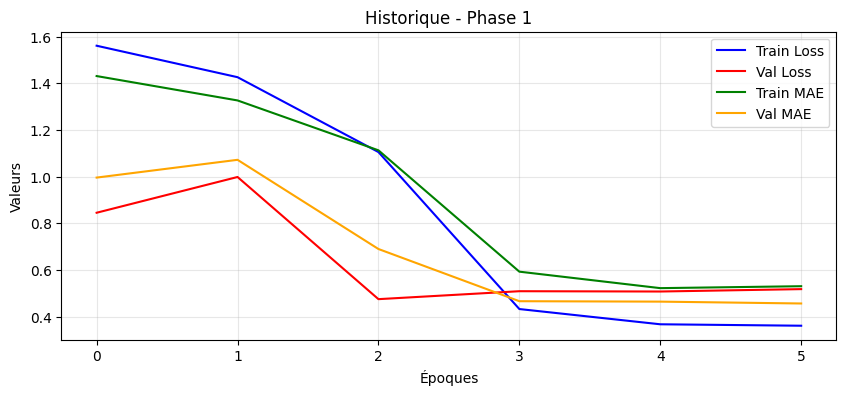

Courbes sauvegardées: /content/drive/MyDrive/ANIP_Challenge/Results/history_Phase 1.png

🚀 PHASE 2: Fine-tuning du backbone (déblocage progressif)
Epoch 1/13
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - loss: 0.7105 - mae: 0.7947
Epoch 1: val_loss improved from 0.47466 to 0.45636, saving model to /content/drive/MyDrive/ANIP_Challenge/Models/best_siamese_model.keras
31/31 ━━━━━━━━━━━━━━━━━━━━ 129s 3s/step - loss: 0.7090 - mae: 0.7945 - val_loss: 0.4564 - val_mae: 0.6557 - learning_rate: 5.0000e-05
Epoch 2/13
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - loss: 0.5826 - mae: 0.7263
Epoch 2: val_loss improved from 0.45636 to 0.44324, saving model to /content/drive/MyDrive/ANIP_Challenge/Models/best_siamese_model.keras
31/31 ━━━━━━━━━━━━━━━━━━━━ 92s 3s/step - loss: 0.5822 - mae: 0.7256 - val_loss: 0.4432 - val_mae: 0.6371 - learning_rate: 5.0000e-05
Epoch 3/13
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - loss: 0.4989 - mae: 0.6657
Epoch 3: val_loss improved from 0.44324 to 0.44036, saving model to /content

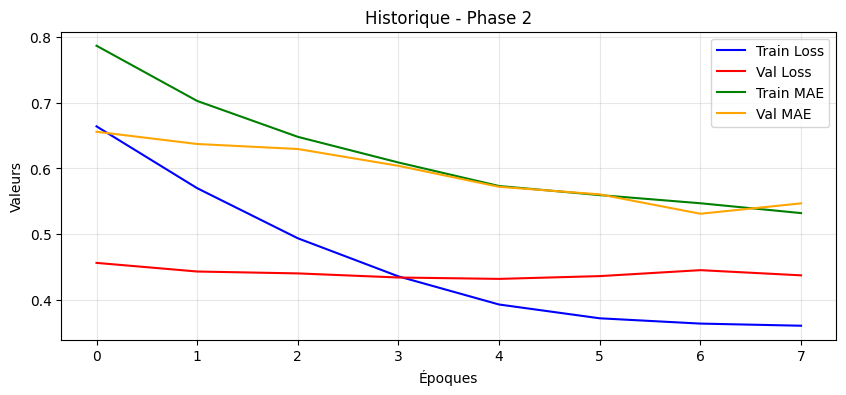

Courbes sauvegardées: /content/drive/MyDrive/ANIP_Challenge/Results/history_Phase 2.png


In [ ]:
# ====================================================================
# Cellule 6: Entraînement Siamese optimisé avec Contrastive Loss
# ====================================================================

import os
import matplotlib.pyplot as plt
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau, CSVLogger, TensorBoard
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import backend as K
from tensorflow.keras.losses import Loss
import datetime

# ----------------------
# Définir Contrastive Loss
# ----------------------
class ContrastiveLoss(Loss):
    def __init__(self, margin=1.0, name="contrastive_loss"):
        super().__init__(name=name)
        self.margin = margin

    def call(self, y_true, y_pred):
        y_true = K.cast(y_true, y_pred.dtype)
        square_pred = K.square(y_pred)
        margin_square = K.square(K.maximum(self.margin - y_pred, 0))
        return K.mean(y_true * square_pred + (1 - y_true) * margin_square)

# ----------------------
# Hyperparamètres ajustés
# ----------------------
patience = CONFIG.get('PATIENCE', 3)
epochs = CONFIG.get('EPOCHS', 20)
learning_rate = CONFIG.get('LEARNING_RATE', 1e-3)
fine_tune_rate = CONFIG.get('FINE_TUNE_RATE', 5e-5)
margin = CONFIG.get('MARGIN', 1.0)

# ----------------------
# Callbacks
# ----------------------
def create_callbacks(model_save_path, patience=3):
    callbacks = []

    early_stopping = EarlyStopping(
        monitor='val_loss',
        patience=patience,
        verbose=1,
        mode='min',
        restore_best_weights=True,
        min_delta=0.001
    )
    callbacks.append(early_stopping)

    checkpoint_path = os.path.join(model_save_path, 'best_siamese_model.keras')
    model_checkpoint = ModelCheckpoint(
        filepath=checkpoint_path,
        monitor='val_loss',
        verbose=1,
        save_best_only=True,
        mode='min',
        save_weights_only=False
    )
    callbacks.append(model_checkpoint)

    reduce_lr = ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1,
        mode='min'
    )
    callbacks.append(reduce_lr)

    # Sauvegarde des logs
    csv_logger = CSVLogger(os.path.join(model_save_path, 'training_log.csv'), append=True)
    callbacks.append(csv_logger)

    # TensorBoard
    log_dir = os.path.join(model_save_path, "logs", datetime.datetime.now().strftime("%Y%m%d-%H%M%S"))
    tensorboard = TensorBoard(log_dir=log_dir, histogram_freq=1)
    callbacks.append(tensorboard)

    return callbacks, checkpoint_path

callbacks, checkpoint_path = create_callbacks(MODEL_SAVE_PATH, patience=patience)
print(f"✓ Callbacks configurés (EarlyStopping patience={patience})")

# ----------------------
# Fonction de visualisation
# ----------------------
def plot_training_history(history, save_path=RESULTS_PATH, phase=""):
    plt.figure(figsize=(10,4))
    plt.plot(history.history['loss'], label='Train Loss', color='blue')
    plt.plot(history.history.get('val_loss', []), label='Val Loss', color='red')
    if 'mae' in history.history:
        plt.plot(history.history['mae'], label='Train MAE', color='green')
        plt.plot(history.history.get('val_mae', []), label='Val MAE', color='orange')
    plt.title(f'Historique - {phase}')
    plt.xlabel('Époques')
    plt.ylabel('Valeurs')
    plt.legend()
    plt.grid(True, alpha=0.3)
    fig_path = os.path.join(save_path, f"history_{phase}.png")
    plt.savefig(fig_path)
    plt.show()
    print(f"Courbes sauvegardées: {fig_path}")

# ----------------------
# Phase 1: entraînement du head (backbone gelé)
# ----------------------
print("\n🚀 PHASE 1: Entraînement du head (backbone gelé)")
phase1_epochs = min(epochs, 7)
siamese_model.compile(
    optimizer=Adam(learning_rate=learning_rate),
    loss=ContrastiveLoss(margin=margin),
    metrics=['mae']  # <-- meilleur suivi que accuracy
)
history_phase1 = siamese_model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=phase1_epochs,
    callbacks=callbacks,
    verbose=1
)
plot_training_history(history_phase1, phase="Phase 1")

# ----------------------
# Phase 2: Fine-tuning progressif du backbone
# ----------------------
print("\n🚀 PHASE 2: Fine-tuning du backbone (déblocage progressif)")
backbone = siamese_model.layers[2]
for layer in backbone.layers[-40:]:  # <-- on débloque plus de couches
    layer.trainable = True

siamese_model.compile(
    optimizer=Adam(learning_rate=fine_tune_rate),
    loss=ContrastiveLoss(margin=margin),
    metrics=['mae']
)

phase2_epochs = epochs - phase1_epochs
if phase2_epochs > 0:
    history_phase2 = siamese_model.fit(
        train_generator,
        validation_data=val_generator,
        epochs=phase2_epochs,
        callbacks=callbacks,
        verbose=1
    )
    plot_training_history(history_phase2, phase="Phase 2")
else:
    print("ℹ️ Phase 2 ignorée (pas assez d'epochs)")


📂 Chargement du modèle depuis /content/drive/MyDrive/ANIP_Challenge/Models/best_siamese_model.keras
🔧 Méthode 1: Recréation de l'architecture...
🏗️ Création du backbone MobileNetV2...
✓ Backbone créé - Embedding dim: 256
✓ Modèle Siamese créé
✓ Modèle compilé
✅ Modèle chargé avec succès (architecture recréée)

📊 ÉVALUATION SUR VALIDATION SET
🔮 Prédiction sur validation set...
✅ 448 prédictions effectuées

🎯 Recherche du seuil optimal...
✅ Seuil optimal trouvé: 0.4724
   - F1-Score: 0.6815
   - Accuracy: 0.6473

📈 MÉTRIQUES FINALES
Seuil de distance: 0.4724
Accuracy:  0.6473 (❌ objectif 80%)
Precision: 0.5417
Recall:    0.9185
F1-Score:  0.6815
ROC-AUC:   0.7324


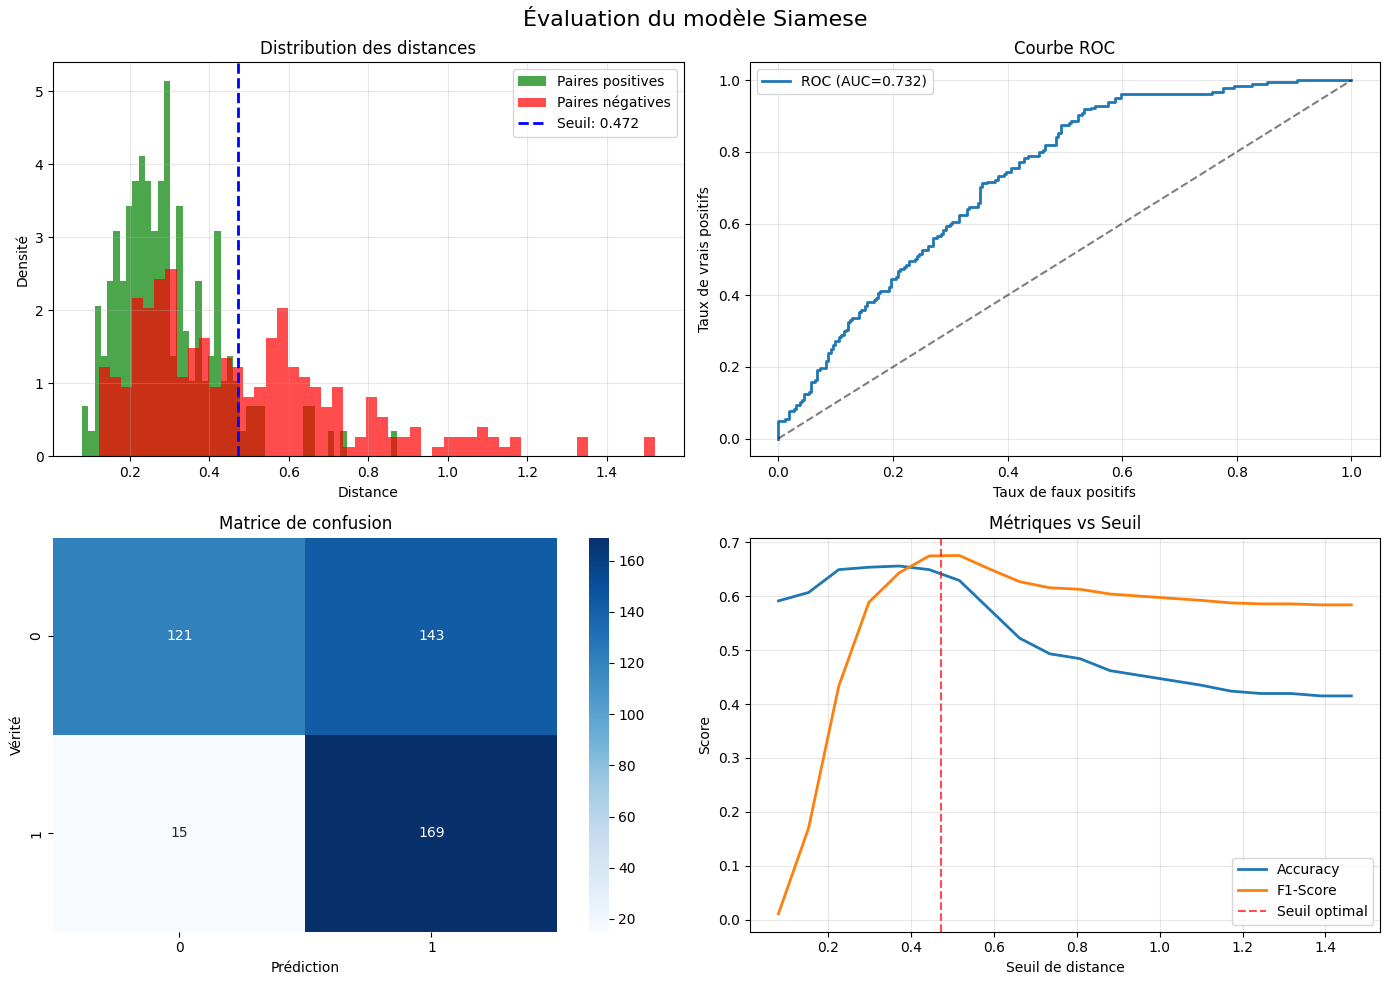


✅ Résultats sauvegardés dans /content/drive/MyDrive/ANIP_Challenge/Results/
   - evaluation_validation.png
   - evaluation_metrics.json

✅ Évaluation terminée

🚀 DÉMARRAGE DE L'INFÉRENCE DE VÉRIFICATION SUR TEST SET
✓ Modèle prêt pour l'inférence
✓ Seuil de distance optimal utilisé : 0.4724

🔎 Recherche des paires dans : /content/anip_data/dataset_tache_1/test
✅ 1000 paires trouvées.


  Vérification des paires: 100%|██████████| 1000/1000 [01:43<00:00,  9.70it/s]



📊 RÉSULTATS DE L'INFÉRENCE
Total paires traitées : 1000
Prédictions 'Même personne' (1) : 689
Prédictions 'Personne différente' (0) : 311

✅ FICHIERS CSV GÉNÉRÉS:
   📄 /content/drive/MyDrive/ANIP_Challenge/Results/submission.csv (pour la soumission)
   📄 /content/drive/MyDrive/ANIP_Challenge/Results/submission_detailed.csv (avec les distances pour analyse)


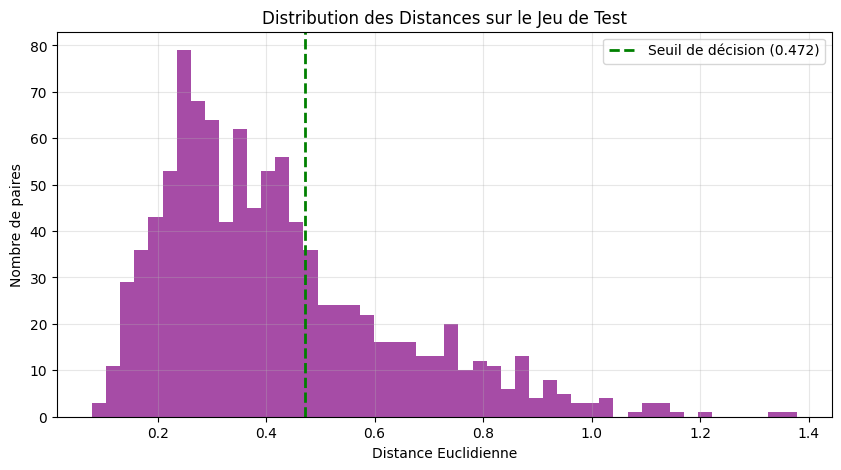

   📊 Graphe des distances sauvegardé : test_distances_distribution.png

🎉 PIPELINE COMPLET TERMINÉ AVEC SUCCÈS !


In [ ]:
# ====================================================================
# Cellule 7: Chargement, Évaluation ET Inférence (VERSION CORRIGÉE)
# ====================================================================

import numpy as np
import cv2
import pandas as pd
from tqdm import tqdm
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve, confusion_matrix)
import matplotlib.pyplot as plt
import seaborn as sns
import json

# ========================================================================
# PARTIE 1: CHARGEMENT DU MODÈLE
# ========================================================================

def load_trained_siamese_model(checkpoint_path):
    """
    Charge le modèle Siamese en recréant l'architecture si nécessaire
    """
    print(f"📂 Chargement du modèle depuis {checkpoint_path}")

    if not os.path.exists(checkpoint_path):
        print(f"❌ Fichier non trouvé: {checkpoint_path}")
        return None, None

    try:
        # SOLUTION 1: Recréer l'architecture puis charger les poids
        print("🔧 Méthode 1: Recréation de l'architecture...")

        # Recréer le modèle Siamese
        siamese_rebuilt = SiameseModel(CONFIG['MODEL'] | CONFIG['TRAINING'] | CONFIG['THRESHOLDS'])
        siamese_rebuilt.create_siamese_model()
        siamese_rebuilt.compile_model()

        # Charger seulement les poids
        siamese_rebuilt.siamese_model.load_weights(checkpoint_path)

        print("✅ Modèle chargé avec succès (architecture recréée)")
        return siamese_rebuilt.siamese_model, siamese_rebuilt.embedding_model

    except Exception as e1:
        print(f"⚠️ Méthode 1 échouée: {e1}")

        try:
            # SOLUTION 2: Custom objects pour Lambda layer
            print("🔧 Méthode 2: Chargement avec custom_objects...")

            def l2_normalize(x):
                return tf.nn.l2_normalize(x, axis=1)

            custom_objects = {
                'ContrastiveLoss': ContrastiveLoss,
                'l2_normalize': l2_normalize,
                'euclidean_distance': lambda vectors: tf.reduce_sum(tf.square(vectors[0] - vectors[1]), axis=1, keepdims=True)
            }

            model = tf.keras.models.load_model(checkpoint_path, custom_objects=custom_objects, compile=False)

            # Recompiler
            model.compile(
                optimizer=Adam(learning_rate=CONFIG['TRAINING']['LEARNING_RATE']),
                loss=ContrastiveLoss(margin=CONFIG['THRESHOLDS']['MARGIN']),
                metrics=['mae']
            )

            print("✅ Modèle chargé avec succès (custom objects)")

            # Extraire l'embedding model
            try:
                embedding_model = model.get_layer(name='embedding_model')
            except:
                embedding_model = None
                print("⚠️ Impossible d'extraire l'embedding_model")

            return model, embedding_model

        except Exception as e2:
            print(f"❌ Méthode 2 échouée: {e2}")
            return None, None

# ----------------------
# Chargement du modèle entraîné
# ----------------------
checkpoint_path = os.path.join(MODEL_SAVE_PATH, 'best_siamese_model.keras')

siamese_model_loaded, embedding_model_loaded = load_trained_siamese_model(checkpoint_path)

if siamese_model_loaded is None:
    print("❌ Impossible de charger le modèle. Utilisation du modèle en mémoire si disponible.")
    if 'siamese_model' in locals():
        siamese_model_loaded = siamese_model
        embedding_model_loaded = embedding_model if 'embedding_model' in locals() else None
        print("✅ Utilisation du modèle en mémoire")
    else:
        print("❌ Aucun modèle disponible pour l'évaluation")

# ========================================================================
# PARTIE 2: ÉVALUATION SUR VALIDATION SET
# ========================================================================

if siamese_model_loaded is not None and 'val_generator' in locals():
    print("\n📊 ÉVALUATION SUR VALIDATION SET")
    print("="*60)

    # Prédictions sur toutes les paires de validation
    print("🔮 Prédiction sur validation set...")

    all_predictions = []
    all_labels = []

    for i in range(len(val_generator)):
        (batch_img1, batch_img2), batch_labels = val_generator[i]
        batch_pred = siamese_model_loaded.predict([batch_img1, batch_img2], verbose=0)

        all_predictions.extend(batch_pred.flatten())
        all_labels.extend(batch_labels.flatten())

    all_predictions = np.array(all_predictions)
    all_labels = np.array(all_labels)

    print(f"✅ {len(all_predictions)} prédictions effectuées")

    # ----------------------
    # Recherche du seuil optimal
    # ----------------------
    print("\n🎯 Recherche du seuil optimal...")

    # Distances à tester
    distance_thresholds = np.linspace(all_predictions.min(), all_predictions.max(), 100)

    best_f1 = 0
    best_threshold = CONFIG['THRESHOLDS']['DISTANCE_THRESHOLD']
    best_metrics = {}

    for threshold in distance_thresholds:
        preds_binary = (all_predictions <= threshold).astype(int)

        if len(np.unique(preds_binary)) > 1:  # Éviter les cas où toutes les prédictions sont identiques
            f1 = f1_score(all_labels, preds_binary, zero_division=0)

            if f1 > best_f1:
                best_f1 = f1
                best_threshold = threshold
                best_metrics = {
                    'threshold': threshold,
                    'accuracy': accuracy_score(all_labels, preds_binary),
                    'precision': precision_score(all_labels, preds_binary, zero_division=0),
                    'recall': recall_score(all_labels, preds_binary, zero_division=0),
                    'f1_score': f1
                }

    print(f"✅ Seuil optimal trouvé: {best_threshold:.4f}")
    print(f"   - F1-Score: {best_metrics['f1_score']:.4f}")
    print(f"   - Accuracy: {best_metrics['accuracy']:.4f}")

    # ----------------------
    # Métriques finales avec seuil optimal
    # ----------------------
    final_preds_binary = (all_predictions <= best_threshold).astype(int)

    accuracy = accuracy_score(all_labels, final_preds_binary)
    precision = precision_score(all_labels, final_preds_binary, zero_division=0)
    recall = recall_score(all_labels, final_preds_binary, zero_division=0)
    f1 = f1_score(all_labels, final_preds_binary, zero_division=0)

    try:
        roc_auc = roc_auc_score(all_labels, -all_predictions)  # -distances car plus petit = plus similaire
    except:
        roc_auc = 0.0

    cm = confusion_matrix(all_labels, final_preds_binary)

    print(f"\n📈 MÉTRIQUES FINALES")
    print("="*60)
    print(f"Seuil de distance: {best_threshold:.4f}")
    print(f"Accuracy:  {accuracy:.4f} ({'✅' if accuracy >= 0.80 else '❌'} objectif 80%)")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1-Score:  {f1:.4f}")
    print(f"ROC-AUC:   {roc_auc:.4f}")

    # ----------------------
    # Visualisation des résultats
    # ----------------------
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle('Évaluation du modèle Siamese', fontsize=16)

    # 1. Distribution des distances
    pos_distances = all_predictions[all_labels == 1]
    neg_distances = all_predictions[all_labels == 0]

    axes[0, 0].hist(pos_distances, bins=50, alpha=0.7, label='Paires positives', color='green', density=True)
    axes[0, 0].hist(neg_distances, bins=50, alpha=0.7, label='Paires négatives', color='red', density=True)
    axes[0, 0].axvline(best_threshold, color='blue', linestyle='--', linewidth=2, label=f'Seuil: {best_threshold:.3f}')
    axes[0, 0].set_xlabel('Distance')
    axes[0, 0].set_ylabel('Densité')
    axes[0, 0].set_title('Distribution des distances')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)

    # 2. Courbe ROC
    fpr, tpr, _ = roc_curve(all_labels, -all_predictions)
    axes[0, 1].plot(fpr, tpr, linewidth=2, label=f'ROC (AUC={roc_auc:.3f})')
    axes[0, 1].plot([0, 1], [0, 1], 'k--', alpha=0.5)
    axes[0, 1].set_xlabel('Taux de faux positifs')
    axes[0, 1].set_ylabel('Taux de vrais positifs')
    axes[0, 1].set_title('Courbe ROC')
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)

    # 3. Matrice de confusion
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1, 0])
    axes[1, 0].set_xlabel('Prédiction')
    axes[1, 0].set_ylabel('Vérité')
    axes[1, 0].set_title('Matrice de confusion')

    # 4. Métriques par seuil
    accuracies, f1s = [], []
    for th in distance_thresholds[::5]:  # Sous-échantillonnage pour performance
        preds = (all_predictions <= th).astype(int)
        if len(np.unique(preds)) > 1:
            accuracies.append(accuracy_score(all_labels, preds))
            f1s.append(f1_score(all_labels, preds, zero_division=0))
        else:
            accuracies.append(0)
            f1s.append(0)

    axes[1, 1].plot(distance_thresholds[::5], accuracies, label='Accuracy', linewidth=2)
    axes[1, 1].plot(distance_thresholds[::5], f1s, label='F1-Score', linewidth=2)
    axes[1, 1].axvline(best_threshold, color='red', linestyle='--', alpha=0.7, label='Seuil optimal')
    axes[1, 1].set_xlabel('Seuil de distance')
    axes[1, 1].set_ylabel('Score')
    axes[1, 1].set_title('Métriques vs Seuil')
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_PATH, 'evaluation_validation.png'), dpi=300, bbox_inches='tight')
    plt.show()

    # ----------------------
    # Sauvegarde des métriques
    # ----------------------
    eval_results = {
        'threshold': float(best_threshold),
        'accuracy': float(accuracy),
        'precision': float(precision),
        'recall': float(recall),
        'f1_score': float(f1),
        'roc_auc': float(roc_auc),
        'confusion_matrix': cm.tolist(),
        'num_samples': len(all_predictions)
    }

    with open(os.path.join(RESULTS_PATH, 'evaluation_metrics.json'), 'w') as f:
        json.dump(eval_results, f, indent=2)

    print(f"\n✅ Résultats sauvegardés dans {RESULTS_PATH}")
    print(f"   - evaluation_validation.png")
    print(f"   - evaluation_metrics.json")

    # Stockage pour utilisation ultérieure
    OPTIMAL_THRESHOLD = best_threshold
    EVAL_METRICS = eval_results

else:
    print("❌ Modèle ou générateur de validation non disponible")
    OPTIMAL_THRESHOLD = CONFIG['THRESHOLDS']['DISTANCE_THRESHOLD']
    EVAL_METRICS = None
    best_threshold = OPTIMAL_THRESHOLD

print("\n✅ Évaluation terminée")

# ========================================================================
# PARTIE 3: INFÉRENCE DE VÉRIFICATION SUR LES PAIRES DE TEST (CORRIGÉ)
# ========================================================================

print("\n" + "="*60)
print("🚀 DÉMARRAGE DE L'INFÉRENCE DE VÉRIFICATION SUR TEST SET")
print("="*60)

# Vérification que le modèle et le seuil sont disponibles
if siamese_model_loaded is None or 'OPTIMAL_THRESHOLD' not in locals():
    print("❌ Modèle ou seuil optimal non disponible. Impossible de procéder à l'inférence.")
else:
    # Configuration
    IMG_SIZE = (CONFIG['DATA']['IMG_HEIGHT'], CONFIG['DATA']['IMG_WIDTH'])
    THRESHOLD = OPTIMAL_THRESHOLD  # Utilisation du seuil calculé à l'étape 2

    print(f"✓ Modèle prêt pour l'inférence")
    print(f"✓ Seuil de distance optimal utilisé : {THRESHOLD:.4f}")

    # ----------------------
    # 1. Fonction pour trouver les paires dans le dossier de test
    # ----------------------
    def find_test_pairs(test_path):
        """
        Analyse le dossier de test et regroupe les images par paires.
        Ex: ('3000_0.jpg', '3000_1.jpg')
        """
        print(f"\n🔎 Recherche des paires dans : {test_path}")
        if not os.path.exists(test_path):
            print(f"❌ ERREUR: Le chemin TEST_PATH n'existe pas!")
            return []

        # Regrouper les fichiers par leur préfixe (ex: '3000')
        files_by_prefix = {}
        for filename in os.listdir(test_path):
            if filename.lower().endswith(('.jpg', '.jpeg', '.png')):
                prefix = filename.split('_')[0]
                if prefix not in files_by_prefix:
                    files_by_prefix[prefix] = []
                files_by_prefix[prefix].append(filename)

        # Créer les paires
        image_pairs = []
        for prefix, files in files_by_prefix.items():
            if len(files) == 2:
                # S'assurer que les fichiers sont dans l'ordre _0 et _1
                files.sort()
                image_pairs.append((files[0], files[1]))
            else:
                print(f"   ⚠️ Préfixe '{prefix}' ignoré : {len(files)} images trouvées au lieu de 2.")

        print(f"✅ {len(image_pairs)} paires trouvées.")
        return image_pairs

    # ----------------------
    # 2. Fonction de prétraitement (identique à la version précédente)
    # ----------------------
    def preprocess_image(img_path):
        try:
            img = cv2.imread(img_path)
            if img is None: raise ValueError("Impossible de lire l'image")
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = cv2.resize(img, IMG_SIZE)
            img = img.astype("float32") / 255.0
            return img, None
        except Exception as e:
            return None, str(e)

    # ----------------------
    # 3. Boucle d'inférence sur les paires
    # ----------------------
    test_pairs = find_test_pairs(TEST_PATH)
    predictions = []

    if test_pairs:
        for img_name1, img_name2 in tqdm(test_pairs, desc="  Vérification des paires"):
            path1 = os.path.join(TEST_PATH, img_name1)
            path2 = os.path.join(TEST_PATH, img_name2)

            # Prétraitement des deux images de la paire
            img1, error1 = preprocess_image(path1)
            img2, error2 = preprocess_image(path2)

            pair_id = img_name1.split('_')[0]

            if img1 is None or img2 is None:
                predictions.append((pair_id, "PREPROCESS_ERROR", 999.0))
                continue

            # Le modèle attend une liste de deux "batchs" d'images
            # Ici, chaque batch ne contient qu'une seule image
            input_data = [np.expand_dims(img1, axis=0), np.expand_dims(img2, axis=0)]

            # Prédiction -> Obtention de la distance
            distance = siamese_model_loaded.predict(input_data, verbose=0)[0][0]

            # Décision basée sur le seuil
            prediction = 1 if distance <= THRESHOLD else 0

            predictions.append((pair_id, prediction, distance))

    # ----------------------
    # 4. Sauvegarde des résultats
    # ----------------------
    if predictions:
        print("\n📊 RÉSULTATS DE L'INFÉRENCE")
        print("="*60)

        # Création du DataFrame pour la soumission
        df_detailed = pd.DataFrame(predictions, columns=["pair_id", "prediction", "distance"])

        # Fichier de soumission simple (format standard)
        df_submission = df_detailed[["pair_id", "prediction"]]

        submission_path = os.path.join(RESULTS_PATH, "submission.csv")
        detailed_path = os.path.join(RESULTS_PATH, "submission_detailed.csv")

        df_submission.to_csv(submission_path, index=False)
        df_detailed.to_csv(detailed_path, index=False)

        # Statistiques
        num_same = df_submission['prediction'].sum()
        num_different = len(df_submission) - num_same
        print(f"Total paires traitées : {len(df_submission)}")
        print(f"Prédictions 'Même personne' (1) : {num_same}")
        print(f"Prédictions 'Personne différente' (0) : {num_different}")

        print(f"\n✅ FICHIERS CSV GÉNÉRÉS:")
        print(f"   📄 {submission_path} (pour la soumission)")
        print(f"   📄 {detailed_path} (avec les distances pour analyse)")

        # Visualisation des distances
        plt.figure(figsize=(10, 5))
        plt.hist(df_detailed['distance'], bins=50, color='purple', alpha=0.7)
        plt.axvline(THRESHOLD, color='green', linestyle='--', linewidth=2, label=f'Seuil de décision ({THRESHOLD:.3f})')
        plt.title('Distribution des Distances sur le Jeu de Test')
        plt.xlabel('Distance Euclidienne')
        plt.ylabel('Nombre de paires')
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.savefig(os.path.join(RESULTS_PATH, 'test_distances_distribution.png'))
        plt.show()

        print(f"   📊 Graphe des distances sauvegardé : test_distances_distribution.png")
        print("\n" + "="*60)
        print("🎉 PIPELINE COMPLET TERMINÉ AVEC SUCCÈS !")
        print("="*60)
    else:
        print("\n❌ Aucune prédiction n'a pu être faite. Vérifiez le contenu de votre dossier TEST_PATH.")